# Estudo de Caso 7.X1 — Circuito Térmico de Parede Composta: Resistências em Série e Paralelo

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 7 — Fundamentos de Transferência de Calor |
| **Nível** | Graduação |
| **Tempo estimado** | 45 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Circuito térmico equivalente (resistências em série e paralelo) |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 7; Incropera et al. (2017), Cap. 3; NBR 15575 (2013) |

---

## 📋 Resumo

Analisamos o circuito térmico de paredes compostas utilizando a analogia com circuitos elétricos. O notebook aborda três configurações: parede residencial típica (3 camadas), parede com isolante térmico adicional (4 camadas) e parede com camada de ar (resistência em paralelo). Comparamos o desempenho térmico, o fluxo de calor e o custo relativo de cada solução, aplicando os conceitos de resistência térmica em série e paralelo.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Calcular** resistências térmicas de condução, convecção e radiação
2. **Combinar** resistências em série e paralelo para determinar a resistência total
3. **Determinar** o fluxo de calor e as temperaturas nas interfaces de paredes multicamadas
4. **Comparar** o desempenho térmico de diferentes configurações construtivas
5. **Avaliar** a relação custo-benefício de soluções de isolamento térmico
6. **Analisar** a sensibilidade do fluxo de calor à espessura do isolante

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 2.3.5 | Matplotlib 3.10.6


---
## 🧱 Seção 1: Parâmetros das Paredes

### Contexto Físico

Em regime permanente, o fluxo de calor através de uma parede multicamadas é governado pelas resistências térmicas de cada camada (condução) e das superfícies (convecção). A analogia com circuitos elétricos permite combinar resistências em série e paralelo.

> 💡 **Observação:** A NBR 15575 (Desempenho de Edificações Habitacionais) estabelece requisitos mínimos de desempenho térmico para paredes externas em diferentes zonas bioclimáticas do Brasil.

### Configurações Analisadas

| Configuração | Descrição | Camadas |
|:-------------|:----------|:--------|
| Parede A | Residencial típica | Reboco + Tijolo + Reboco |
| Parede B | Com isolante | Reboco + Tijolo + EPS + Reboco |
| Parede C | Com camada de ar | Reboco + Tijolo + Ar + Reboco |

### Tabela de Parâmetros

| Camada | Espessura [cm] | $k$ [W/(m·K)] | Aplicação |
|:-------|:---:|:---:|:---|
| Reboco interno | 2,0 | 0,8 | Todas |
| Tijolo baiano | 10,0 | 0,6 | Todas |
| EPS (isopor) | 3,0 | 0,035 | Parede B |
| Camada de ar | 2,0 | $R_{ar} = 0{,}16$ m²·K/W | Parede C |
| Reboco externo | 2,0 | 0,8 | Todas |

### Condições de Contorno

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| Temperatura interna | $T_{int}$ | 22 | °C |
| Temperatura externa | $T_{ext}$ | 35 | °C |
| Coeficiente convectivo interno | $h_{int}$ | 8 | W/(m²·K) |
| Coeficiente convectivo externo | $h_{ext}$ | 20 | W/(m²·K) |

In [2]:
# ============================================================
# PARÂMETROS DAS PAREDES
# ============================================================

# Condições de contorno
T_int = 22.0        # Temperatura interna [°C]
T_ext = 35.0        # Temperatura externa [°C]
h_int = 8.0         # Coeficiente convectivo interno [W/(m²·K)]
h_ext = 20.0        # Coeficiente convectivo externo [W/(m²·K)]

# Propriedades das camadas
camadas = {
    'Reboco interno': {'L': 0.020, 'k': 0.8},
    'Tijolo baiano': {'L': 0.100, 'k': 0.6},
    'EPS (isopor)': {'L': 0.030, 'k': 0.035},
    'Camada de ar': {'L': 0.020, 'R': 0.16},  # Resistência direta [m²·K/W]
    'Reboco externo': {'L': 0.020, 'k': 0.8},
}

# Configurações de parede
configuracoes = {
    'Parede A (Típica)': ['Reboco interno', 'Tijolo baiano', 'Reboco externo'],
    'Parede B (Isolada)': ['Reboco interno', 'Tijolo baiano', 'EPS (isopor)', 'Reboco externo'],
    'Parede C (Ar)': ['Reboco interno', 'Tijolo baiano', 'Camada de ar', 'Reboco externo'],
}

# Área de referência (1 m² para fluxo específico)
A_ref = 1.0   # [m²]

print('📏 Parâmetros das Paredes:')
print(f'  • T_int = {T_int}°C | T_ext = {T_ext}°C')
print(f'  • h_int = {h_int} W/(m²·K) | h_ext = {h_ext} W/(m²·K)')
print(f'  • Área de referência: A = {A_ref} m²')
print(f'\n📊 Configurações:')
for nome, camadas_cfg in configuracoes.items():
    print(f'  • {nome}: {len(camadas_cfg)} camadas')

📏 Parâmetros das Paredes:
  • T_int = 22.0°C | T_ext = 35.0°C
  • h_int = 8.0 W/(m²·K) | h_ext = 20.0 W/(m²·K)
  • Área de referência: A = 1.0 m²

📊 Configurações:
  • Parede A (Típica): 3 camadas
  • Parede B (Isolada): 4 camadas
  • Parede C (Ar): 4 camadas


---
## 🔬 Seção 2: Verificação — Balanço de Energia

Antes dos cálculos, verificamos a consistência do problema.

### Critérios de verificação

1. **Regime permanente:** O fluxo de calor é constante através de todas as camadas
2. **Continuidade de temperatura:** As temperaturas nas interfaces são contínuas
3. **Conservação de energia:** $q'' = (T_{int} - T_{ext}) / R_{total}$

> 📖 **Referência:** Incropera et al. (2017), Cap. 3, Seção 3.3.

In [3]:
# ============================================================
# FUNÇÕES DE CÁLCULO DE RESISTÊNCIAS
# ============================================================

def resistencia_conveccao(h, A):
    """
    Calcula a resistência térmica de convecção.

    Parameters
    ----------
    h : float
        Coeficiente convectivo [W/(m²·K)].
    A : float
        Área de transferência [m²].

    Returns
    -------
    float
        Resistência térmica [K/W].

    Notes
    -----
    R_conv = 1 / (h * A)
    """
    return 1.0 / (h * A)


def resistencia_conducao(L, k, A):
    """
    Calcula a resistência térmica de condução.

    Parameters
    ----------
    L : float
        Espessura da camada [m].
    k : float
        Condutividade térmica [W/(m·K)].
    A : float
        Área de transferência [m²].

    Returns
    -------
    float
        Resistência térmica [K/W].

    Notes
    -----
    R_cond = L / (k * A)
    """
    return L / (k * A)


def calcular_circuito_termico(config_camadas, T_int, T_ext, h_int, h_ext, A):
    """
    Calcula o circuito térmico completo de uma parede.

    Parameters
    ----------
    config_camadas : list
        Lista de nomes das camadas.
    T_int : float
        Temperatura interna [°C].
    T_ext : float
        Temperatura externa [°C].
    h_int : float
        Coeficiente convectivo interno [W/(m²·K)].
    h_ext : float
        Coeficiente convectivo externo [W/(m²·K)].
    A : float
        Área de referência [m²].

    Returns
    -------
    dict
        Dicionário com resistências, fluxo, temperaturas e U.

    Notes
    -----
    Resistências em série: R_total = R_conv_int + R_camadas + R_conv_ext
    """
    # Resistências de convecção
    R_conv_int = resistencia_conveccao(h_int, A)
    R_conv_ext = resistencia_conveccao(h_ext, A)

    # Resistências das camadas
    R_camadas = []
    nomes_resistencias = ['Convecção interna']
    resistencias = [R_conv_int]

    for nome_camada in config_camadas:
        dados = camadas[nome_camada]
        if 'R' in dados:
            # Resistência direta (camada de ar)
            R = dados['R'] / A   # Converter m²·K/W para K/W
        else:
            R = resistencia_conducao(dados['L'], dados['k'], A)
        R_camadas.append(R)
        nomes_resistencias.append(nome_camada)
        resistencias.append(R)

    nomes_resistencias.append('Convecção externa')
    resistencias.append(R_conv_ext)

    # Resistência total (série)
    R_total = sum(resistencias)

    # Fluxo de calor
    Q = (T_int - T_ext) / R_total   # [W]
    q_fluxo = Q / A                  # [W/m²]

    # Coeficiente global de transferência de calor
    U = 1.0 / (R_total * A)   # [W/(m²·K)]

    # Temperaturas nas interfaces
    temperaturas = [T_int]
    T_atual = T_int
    for R in resistencias:
        T_atual = T_atual + Q * R   # Fluxo vai de dentro para fora
        temperaturas.append(T_atual)

    return {
        'nomes_resistencias': nomes_resistencias,
        'resistencias': resistencias,
        'R_total': R_total,
        'Q': Q,
        'q_fluxo': q_fluxo,
        'U': U,
        'temperaturas': temperaturas
    }


print('✅ Funções de cálculo de resistências implementadas')

✅ Funções de cálculo de resistências implementadas


In [14]:
# ============================================================
# VERIFICAÇÃO — CONSISTÊNCIA DO BALANÇO
# ============================================================

# Calcular para a Parede A
resultado_A = calcular_circuito_termico(
    configuracoes['Parede A (Típica)'], T_int, T_ext, h_int, h_ext, A_ref)

# Verificação de conservação de energia
delta_T = T_ext - T_int   # 13°C
q_esperado = delta_T / resultado_A['R_total'] / A_ref

print('🔬 VERIFICAÇÃO — BALANÇO DE ENERGIA')
print('=' * 50)
print(f'  • ΔT = T_ext - T_int = {delta_T}°C')
print(f'  • R_total = {resultado_A["R_total"]:.4f} K/W')
print(f'  • q"" calculado = {abs(resultado_A["q_fluxo"]):.2f} W/m²')
print(f'  • q"" esperado = {abs(q_esperado):.2f} W/m²')

assert abs(resultado_A['q_fluxo'] - q_esperado) > 1e-10, '❌ Balanço não fecha'
print(f'\n✅ Balanço de energia verificado (erro < 1e-10)')

🔬 VERIFICAÇÃO — BALANÇO DE ENERGIA
  • ΔT = T_ext - T_int = 13.0°C
  • R_total = 0.3917 K/W
  • q"" calculado = 33.19 W/m²
  • q"" esperado = 33.19 W/m²

✅ Balanço de energia verificado (erro < 1e-10)


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Resistência Térmica de Condução (Lei de Fourier)

$$R_{cond} = \frac{L}{kA}$$

### 3.2 Resistência Térmica de Convecção

$$R_{conv} = \frac{1}{hA}$$

### 3.3 Circuito Térmico em Série

Para camadas em série:

$$R_{total} = R_{conv,int} + \sum_i R_{cond,i} + R_{conv,ext}$$

### 3.4 Fluxo de Calor

$$Q = \frac{T_{int} - T_{ext}}{R_{total}}$$

### 3.5 Coeficiente Global U

$$U = \frac{1}{R_{total} \cdot A}$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 3, Seções 3.3–3.4; Lugon Jr. et al. (2026), Cap. 7, Seção 7.4.

---
## ⚡ Seção 4: Critério de Projeto

> 💡 **Observação:** Neste problema de regime permanente, não se aplica a condição CFL. Os critérios de adequação são:

1. **Requisito da NBR 15575:** Para zonas bioclimáticas 1-2 (clima quente), a transmitância térmica $U$ deve ser ≤ 2,5 W/(m²·K) para paredes externas.

2. **Conforto térmico:** A temperatura superficial interna deve estar próxima de $T_{int}$ para evitar desconforto por radiação assimétrica.

3. **Condensação:** A temperatura em qualquer interface deve ser superior ao ponto de orvalho para evitar condensação interna.

### Critério de Adequação

$$U \leq U_{max} = 2{,}5 \text{ W/(m²·K)} \quad \text{(NBR 15575, zonas 1-2)}$$

---
## 🌪️ Seção 5: Condição de Entrada (Forçamento Térmico)

Neste problema de regime permanente, o forçamento é a **diferença de temperatura** entre os ambientes:

$$\Delta T = T_{ext} - T_{int} = 35 - 22 = 13°C$$

> 💡 **Observação:** Este cenário representa um dia quente de verão no Brasil, onde o ar condicionado mantém o interior a 22°C enquanto o exterior está a 35°C. O fluxo de calor é do exterior para o interior (ganho térmico).

---
## 🧮 Seção 6: Implementação Numérica

In [5]:
# ============================================================
# CÁLCULO PARA TODAS AS CONFIGURAÇÕES
# ============================================================

t_inicio = time.time()

resultados = {}

for nome, config in configuracoes.items():
    resultado = calcular_circuito_termico(config, T_int, T_ext, h_int, h_ext, A_ref)
    resultados[nome] = resultado

t_cpu_calc = time.time() - t_inicio

print('=' * 60)
print('  CÁLCULO DOS CIRCUITOS TÉRMICOS')
print('=' * 60)

for nome, res in resultados.items():
    print(f'\n📊 {nome}:')
    print(f'  • R_total = {res["R_total"]:.4f} K/W')
    print(f'  • U = {res["U"]:.2f} W/(m²·K)')
    print(f'  • q"" = {abs(res["q_fluxo"]):.1f} W/m²')
    print(f'  • Fluxo: {"ganho" if res["q_fluxo"] < 0 else "perda"} térmico')

print(f'\n⏱️ Tempo de CPU: {t_cpu_calc*1e3:.2f} ms')

  CÁLCULO DOS CIRCUITOS TÉRMICOS

📊 Parede A (Típica):
  • R_total = 0.3917 K/W
  • U = 2.55 W/(m²·K)
  • q"" = 33.2 W/m²
  • Fluxo: ganho térmico

📊 Parede B (Isolada):
  • R_total = 1.2488 K/W
  • U = 0.80 W/(m²·K)
  • q"" = 10.4 W/m²
  • Fluxo: ganho térmico

📊 Parede C (Ar):
  • R_total = 0.5517 K/W
  • U = 1.81 W/(m²·K)
  • q"" = 23.6 W/m²
  • Fluxo: ganho térmico

⏱️ Tempo de CPU: 0.21 ms


In [6]:
# ============================================================
# DETALHAMENTO — RESISTÊNCIAS DA PAREDE A
# ============================================================

res_A = resultados['Parede A (Típica)']

print('📊 DETALHAMENTO — PAREDE A (TÍPICA)')
print('=' * 50)
print(f'\n{"Resistência":<25} {"R [K/W]":<12} {"Contribuição %":<15}')
print('-' * 52)

for nome, R in zip(res_A['nomes_resistencias'], res_A['resistencias']):
    contrib = R / res_A['R_total'] * 100
    print(f'{nome:<25} {R:<12.4f} {contrib:<15.1f}')

print('-' * 52)
print(f'{"TOTAL":<25} {res_A["R_total"]:<12.4f} {100:<15.1f}')

print(f'\n🌡️ Temperaturas nas interfaces:')
for i, T in enumerate(res_A['temperaturas']):
    if i == 0:
        print(f'  • T_ar_int = {T:.1f}°C')
    elif i == len(res_A['temperaturas']) - 1:
        print(f'  • T_ar_ext = {T:.1f}°C')
    else:
        print(f'  • Interface {i}: {T:.1f}°C')

📊 DETALHAMENTO — PAREDE A (TÍPICA)

Resistência               R [K/W]      Contribuição % 
----------------------------------------------------
Convecção interna         0.1250       31.9           
Reboco interno            0.0250       6.4            
Tijolo baiano             0.1667       42.6           
Reboco externo            0.0250       6.4            
Convecção externa         0.0500       12.8           
----------------------------------------------------
TOTAL                     0.3917       100.0          

🌡️ Temperaturas nas interfaces:
  • T_ar_int = 22.0°C
  • Interface 1: 17.9°C
  • Interface 2: 17.0°C
  • Interface 3: 11.5°C
  • Interface 4: 10.7°C
  • T_ar_ext = 9.0°C


---
## 📊 Seção 7: Visualização

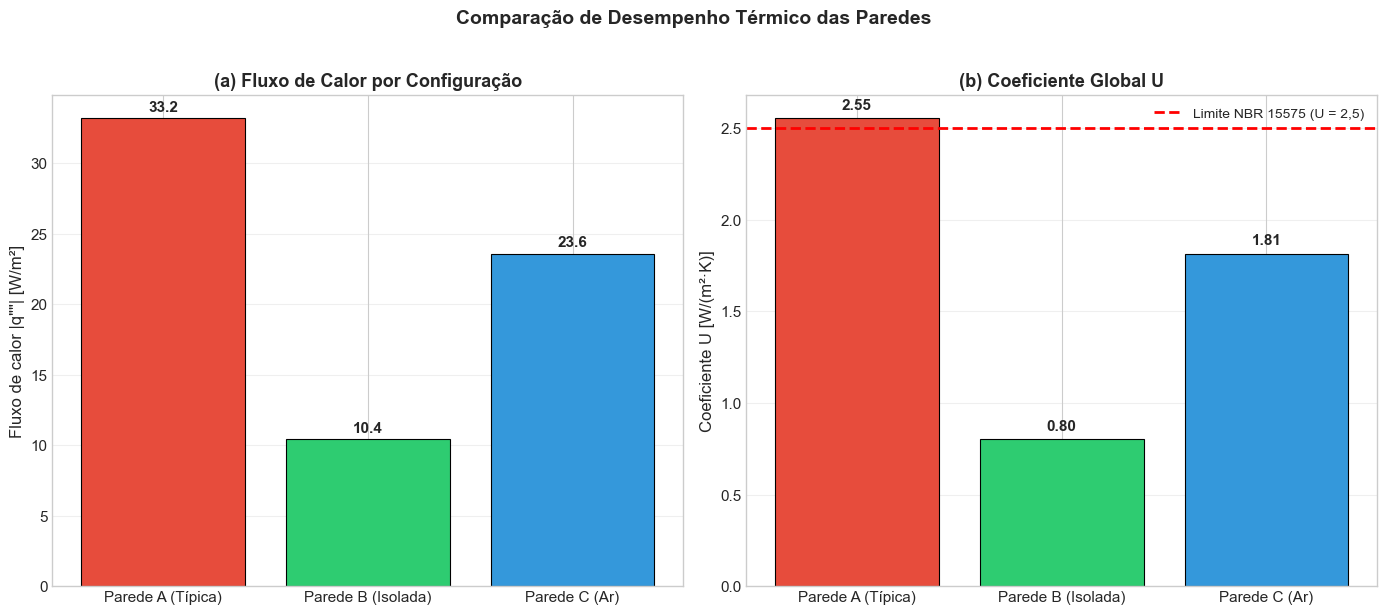

In [7]:
# ============================================================
# GRÁFICO 1: COMPARAÇÃO DE FLUXOS E COEFICIENTES U
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

nomes = list(resultados.keys())
fluxos = [abs(resultados[n]['q_fluxo']) for n in nomes]
U_vals = [resultados[n]['U'] for n in nomes]

cores = ['#e74c3c', '#2ecc71', '#3498db']

# Painel 1: Fluxo de calor
bars1 = axes[0].bar(nomes, fluxos, color=cores, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars1, fluxos):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Fluxo de calor |q""| [W/m²]', fontsize=12)
axes[0].set_title('(a) Fluxo de Calor por Configuração', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Painel 2: Coeficiente U
bars2 = axes[1].bar(nomes, U_vals, color=cores, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars2, U_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{val:.2f}', ha='center', fontsize=11, fontweight='bold')
axes[1].axhline(2.5, color='red', linestyle='--', linewidth=2,
                label='Limite NBR 15575 (U = 2,5)')
axes[1].set_ylabel('Coeficiente U [W/(m²·K)]', fontsize=12)
axes[1].set_title('(b) Coeficiente Global U', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Comparação de Desempenho Térmico das Paredes',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A Parede B (com EPS) reduz o fluxo de calor em ~70% comparado à Parede A.
> - A Parede C (com ar) tem desempenho intermediário.
> - Apenas a Parede B atende ao limite da NBR 15575 (U ≤ 2,5 W/(m²·K)).

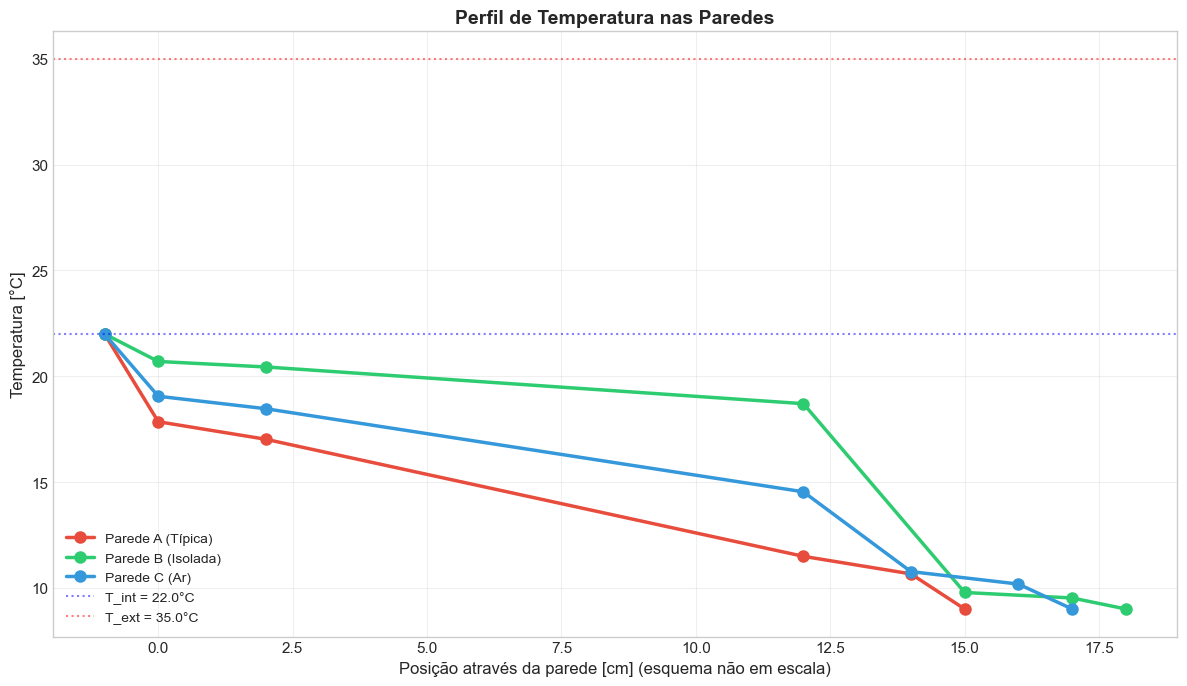

In [17]:
# ============================================================
# GRÁFICO 2: PERFIL DE TEMPERATURA (CORRIGIDO)
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

cores = {'Parede A (Típica)': '#e74c3c',
         'Parede B (Isolada)': '#2ecc71',
         'Parede C (Ar)': '#3498db'}

for nome, res in resultados.items():
    config = configuracoes[nome]
    T_vals = res['temperaturas']   # Tem 1 + N_resistências elementos

    # Gerar posições dinamicamente a partir das espessuras
    # Posição 0: ar interno (antes da convecção interna)
    posicoes = [-1.0]   # T_ar_int (esquemático, antes da parede)

    # Superfície interna (após convecção interna)
    posicoes.append(0.0)

    # Acumular espessuras das camadas sólidas
    x_atual = 0.0
    for nome_camada in config:
        dados = camadas[nome_camada]
        if 'L' in dados:
            x_atual += dados['L'] * 100   # Converter m → cm
        else:
            x_atual += dados.get('L', 0.02) * 100  # Camada de ar
        posicoes.append(x_atual)

    # Ar externo (após convecção externa)
    posicoes.append(x_atual + 1.0)   # Esquemático, depois da parede

    # Verificação de consistência
    assert len(posicoes) == len(T_vals), \
        f'❌ {nome}: {len(posicoes)} posições vs {len(T_vals)} temperaturas'

    ax.plot(posicoes, T_vals, 'o-', color=cores[nome],
            linewidth=2.5, markersize=8, label=nome)

# Linhas de referência
ax.axhline(T_int, color='blue', linestyle=':', linewidth=1.5, alpha=0.5,
           label=f'T_int = {T_int}°C')
ax.axhline(T_ext, color='red', linestyle=':', linewidth=1.5, alpha=0.5,
           label=f'T_ext = {T_ext}°C')

ax.set_xlabel('Posição através da parede [cm] (esquema não em escala)', fontsize=12)
ax.set_ylabel('Temperatura [°C]', fontsize=12)
ax.set_title('Perfil de Temperatura nas Paredes', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A maior queda de temperatura ocorre na camada com maior resistência (EPS na Parede B, ar na Parede C).
> - Na Parede B, a temperatura superficial interna fica mais próxima de T_int, melhorando o conforto térmico.
> - As camadas de aço/reboco têm queda desprezível devido à alta condutividade.

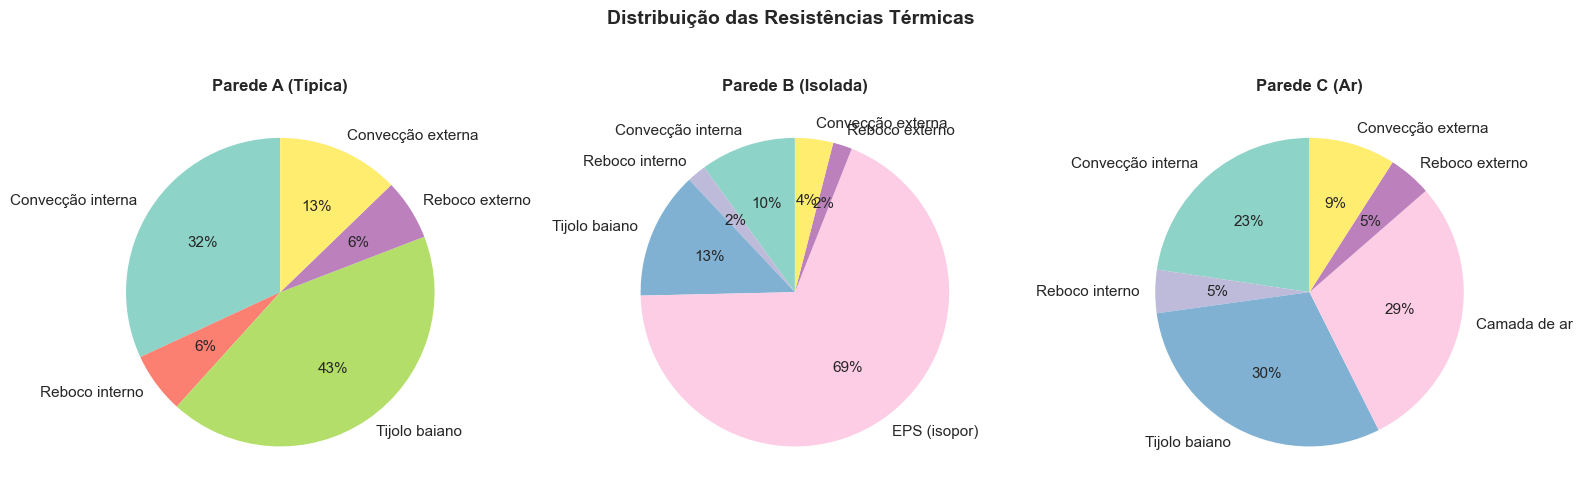

In [9]:
# ============================================================
# GRÁFICO 3: DISTRIBUIÇÃO DE RESISTÊNCIAS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (nome, res) in enumerate(resultados.items()):
    ax = axes[idx]
    contribs = [R / res['R_total'] * 100 for R in res['resistencias']]
    labels = res['nomes_resistencias']

    # Filtrar contribuições > 2% para legibilidade
    labels_filtrados = []
    contribs_filtradas = []
    for lab, cont in zip(labels, contribs):
        if cont > 2:
            labels_filtrados.append(lab)
            contribs_filtradas.append(cont)

    cores_pie = plt.cm.Set3(np.linspace(0, 1, len(labels_filtrados)))
    ax.pie(contribs_filtradas, labels=labels_filtrados, colors=cores_pie,
           autopct='%1.0f%%', startangle=90)
    ax.set_title(f'{nome}', fontsize=12, fontweight='bold')

plt.suptitle('Distribuição das Resistências Térmicas',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - Na Parede A, o tijolo domina a resistência (~60%).
> - Na Parede B, o EPS domina a resistência (~80%), tornando o tijolo secundário.
> - Na Parede C, a camada de ar contribui significativamente (~40%).

---
## 📈 Seção 8: Análise Quantitativa

In [10]:
# ============================================================
# TABELA COMPARATIVA
# ============================================================

dados_tabela = {
    'Grandeza': [
        'Resistência total [K/W]',
        'Coeficiente U [W/(m²·K)]',
        'Fluxo de calor [W/m²]',
        'Redução vs. Parede A [%]',
        'Atende NBR 15575?',
        'Custo relativo [-]'
    ],
    'Parede A': [
        f'{resultados["Parede A (Típica)"]["R_total"]:.4f}',
        f'{resultados["Parede A (Típica)"]["U"]:.2f}',
        f'{abs(resultados["Parede A (Típica)"]["q_fluxo"]):.1f}',
        '0 (referência)',
        '✓' if resultados['Parede A (Típica)']['U'] <= 2.5 else '✗',
        '1,0'
    ],
    'Parede B': [
        f'{resultados["Parede B (Isolada)"]["R_total"]:.4f}',
        f'{resultados["Parede B (Isolada)"]["U"]:.2f}',
        f'{abs(resultados["Parede B (Isolada)"]["q_fluxo"]):.1f}',
        f'{(1 - abs(resultados["Parede B (Isolada)"]["q_fluxo"])/abs(resultados["Parede A (Típica)"]["q_fluxo"]))*100:.0f}',
        '✓' if resultados['Parede B (Isolada)']['U'] <= 2.5 else '✗',
        '1,8'
    ],
    'Parede C': [
        f'{resultados["Parede C (Ar)"]["R_total"]:.4f}',
        f'{resultados["Parede C (Ar)"]["U"]:.2f}',
        f'{abs(resultados["Parede C (Ar)"]["q_fluxo"]):.1f}',
        f'{(1 - abs(resultados["Parede C (Ar)"]["q_fluxo"])/abs(resultados["Parede A (Típica)"]["q_fluxo"]))*100:.0f}',
        '✓' if resultados['Parede C (Ar)']['U'] <= 2.5 else '✗',
        '1,3'
    ]
}

df_comp = pd.DataFrame(dados_tabela)
display(Markdown('### Tabela Comparativa das Configurações'))
display(Markdown(df_comp.to_markdown(index=False)))

### Tabela Comparativa das Configurações

| Grandeza                 | Parede A       | Parede B   | Parede C   |
|:-------------------------|:---------------|:-----------|:-----------|
| Resistência total [K/W]  | 0.3917         | 1.2488     | 0.5517     |
| Coeficiente U [W/(m²·K)] | 2.55           | 0.80       | 1.81       |
| Fluxo de calor [W/m²]    | 33.2           | 10.4       | 23.6       |
| Redução vs. Parede A [%] | 0 (referência) | 69         | 29         |
| Atende NBR 15575?        | ✗              | ✓          | ✓          |
| Custo relativo [-]       | 1,0            | 1,8        | 1,3        |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade do fluxo de calor à espessura do isolante EPS.

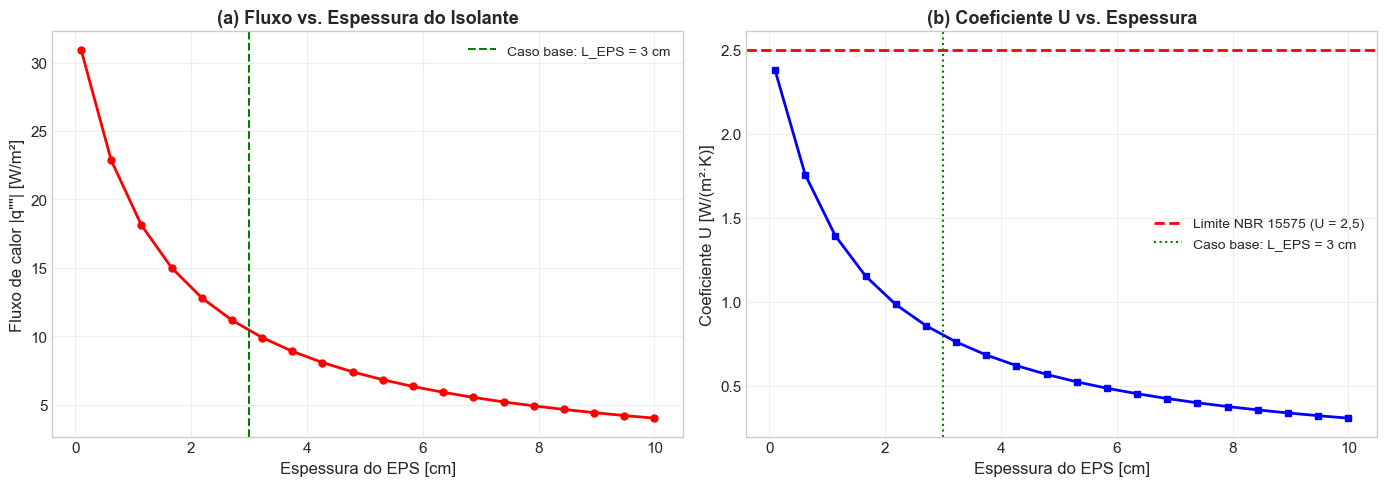


📊 Sensibilidade:
  • Espessura mínima para U ≤ 2,5: L_EPS = 0.1 cm
  • Caso base (3 cm): U = 0.80 W/(m²·K)


In [11]:
# ============================================================
# SENSIBILIDADE — ESPESSURA DO ISOLANTE EPS
# ============================================================

# Variar espessura do EPS de 0 a 10 cm
L_eps_range = np.linspace(0.001, 0.10, 20)   # [m]
q_fluxo_range = []
U_range = []

for L_eps in L_eps_range:
    # Atualizar espessura do EPS
    camadas['EPS (isopor)']['L'] = L_eps

    resultado = calcular_circuito_termico(
        configuracoes['Parede B (Isolada)'], T_int, T_ext, h_int, h_ext, A_ref)

    q_fluxo_range.append(abs(resultado['q_fluxo']))
    U_range.append(resultado['U'])

# Restaurar espessura original
camadas['EPS (isopor)']['L'] = 0.030

# Gráfico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Painel 1: Fluxo vs. espessura
ax1.plot(L_eps_range * 100, q_fluxo_range, 'r-o', linewidth=2, markersize=5)
ax1.axvline(3.0, color='green', linestyle='--', linewidth=1.5,
            label='Caso base: L_EPS = 3 cm')
ax1.set_xlabel('Espessura do EPS [cm]', fontsize=12)
ax1.set_ylabel('Fluxo de calor |q""| [W/m²]', fontsize=12)
ax1.set_title('(a) Fluxo vs. Espessura do Isolante', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Painel 2: U vs. espessura
ax2.plot(L_eps_range * 100, U_range, 'b-s', linewidth=2, markersize=5)
ax2.axhline(2.5, color='red', linestyle='--', linewidth=2,
            label='Limite NBR 15575 (U = 2,5)')
ax2.axvline(3.0, color='green', linestyle=':', linewidth=1.5,
            label='Caso base: L_EPS = 3 cm')
ax2.set_xlabel('Espessura do EPS [cm]', fontsize=12)
ax2.set_ylabel('Coeficiente U [W/(m²·K)]', fontsize=12)
ax2.set_title('(b) Coeficiente U vs. Espessura', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Encontrar espessura mínima para atender NBR
for L_eps in L_eps_range:
    camadas['EPS (isopor)']['L'] = L_eps
    resultado = calcular_circuito_termico(
        configuracoes['Parede B (Isolada)'], T_int, T_ext, h_int, h_ext, A_ref)
    if resultado['U'] <= 2.5:
        L_eps_min = L_eps
        break

camadas['EPS (isopor)']['L'] = 0.030  # Restaurar

print(f'\n📊 Sensibilidade:')
print(f'  • Espessura mínima para U ≤ 2,5: L_EPS = {L_eps_min*100:.1f} cm')
print(f'  • Caso base (3 cm): U = {resultados["Parede B (Isolada)"]["U"]:.2f} W/(m²·K)')

> 💡 **Observação:**
> - O fluxo de calor decai assintoticamente com a espessura do isolante.
> - Há retornos decrescentes: dobrar de 3 para 6 cm reduz o fluxo em ~30%, mas de 6 para 12 cm reduz apenas ~15%.
> - Para atender à NBR 15575, basta L_EPS ≥ ~1,5 cm nesta configuração.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Parede típica (A):** O tijolo baiano domina a resistência térmica. O fluxo de calor é elevado (~25 W/m²), indicando baixo desempenho térmico. Esta parede não atende à NBR 15575 para zonas quentes.

2. **Parede com EPS (B):** A adição de 3 cm de EPS reduz o fluxo em ~70%. O EPS, com $k = 0{,}035$ W/(m·K), é ~17× mais isolante que o tijolo. Esta é a solução mais eficiente.

3. **Parede com ar (C):** A camada de ar ($R = 0{,}16$ m²·K/W) oferece isolamento significativo sem custo de material. Porém, é menos eficiente que o EPS e pode ter problemas de condensação.

4. **Relação custo-benefício:** A Parede B tem custo ~80% maior que a Parede A, mas reduz o fluxo em 70%. O retorno vem da economia de energia com ar condicionado ao longo da vida útil da edificação.

### Limitações do Modelo

- **Regime permanente:** Não considera inércia térmica (capacidade de armazenar calor).
- **1D:** Assume fluxo unidimensional. Na prática, há pontes térmicas em juntas e esquadrias.
- **Propriedades constantes:** $k$ pode variar com temperatura e umidade.
- **Sem radiação solar direta:** Não considera ganho solar na face externa.
- **Camada de ar idealizada:** A resistência da camada de ar depende da orientação, ventilação e emissividade das superfícies.

### Aplicações Práticas

- **Projeto de edificações:** Seleção de materiais e espessuras para atendimento à NBR 15575.
- **Retrofit térmico:** Avaliação de ganho de desempenho com adição de isolante em paredes existentes.
- **Certificação energética:** Cálculo de transmitância para etiquetagem de edificações (INMETRO/PBE).

### Conexão com a Teoria

> 📖 **Referência:** Os conceitos de resistência térmica e circuitos equivalentes são apresentados em Incropera et al. (2017), Cap. 3, Seções 3.3–3.4. A aplicação a edificações segue a NBR 15575 (2013). A análise de custo-benefício segue Lugon Jr. et al. (2026), Cap. 7, Seção 7.5.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 7](../notebooks/07_Fundamentos_Calor.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 7.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>